# Creating Figures (Retirement v4)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime

start_time = time.time()

In [2]:
import importlib.util
from pathlib import Path

module_path = Path("Endogenous-Retirement-Search-v4.py")
spec = importlib.util.spec_from_file_location("retirement_search", module_path)
retirement_search = importlib.util.module_from_spec(spec)
spec.loader.exec_module(retirement_search)

RetiringDeaton = retirement_search.RetiringDeaton

In [3]:
# +
CRRA = 1.0
DiscFac = 0.98
Rfree = 1.0
DisUtil = 1.0
T = 20
sigma_s = 0.0
sigma_t = 0.0
sigma_xi = 0.0
sigma_phi = 0.0
prob_opt = 1.0
smoothtype = 'type1'

aXtraMin = 1e-6
aXtraMax = 400.0
aXtraCount = 6000
aXtraExtra = () # this is additional points to add (for precision around know problematic areas)
aXtraNestFac = 1 # this is the times to nest

YWork = 20.0
YRet = 0.0 # normalized relative to work
TranShkStd = [0.000]*T
TranShkCount = 1
PermShkStd = [0.0]*T
PermShkCount = 1
TasteShkCount = 1
PhiShkCount = 1
EGMCount = 7000
saveCommon = False #True #False
T_retire = 0 # not applicable, it's endogenous
T_cycle = T
LivPrb = [1.0]*T
PermGroFac = [1.0]*T
UnempPrb = 0.0
UnempPrbRet = 0.0
IncUnemp = 0.0
IncUnempRet = 0.0


retiring_params = {'CRRA' : CRRA,
                   'Rfree' : Rfree,
                   'DiscFac' : DiscFac,
                   'DisUtil' : DisUtil,
                   'T' : T,
                   'sigma_s' : sigma_s,
                   'sigma_t' : sigma_t,
                   'sigma_xi' : sigma_xi,
                   'sigma_phi' : sigma_phi,
                   'prob_opt' : prob_opt,
                   'smoothtype' : smoothtype,
                   'aXtraMin' : aXtraMin,
                   'aXtraMax' : aXtraMax,
                   'aXtraCount' : aXtraCount,
                   'aXtraExtra' : aXtraExtra,
                   'aXtraNestFac' : aXtraNestFac,
                   'UnempPrb' : UnempPrb,
                   'UnempPrbRet' : UnempPrbRet,
                   'IncUnemp' : IncUnemp,
                   'IncUnempRet' : IncUnempRet,
                   'YWork' : YWork,
                   'YRet' : YRet,
                   'TranShkStd' : TranShkStd,
                   'TranShkCount' : TranShkCount,
                   'PermShkStd' : PermShkStd,
                   'PermShkCount' : PermShkCount,
                   'TasteShkCount' : TasteShkCount,
                   'PhiShkCount' : PhiShkCount,
                   'EGMCount' : EGMCount,
                   'T_retire' : T_retire,
                   'T_cycle' : T_cycle,
                   'LivPrb' : LivPrb,
                   'PermGroFac' : PermGroFac,
                   'saveCommon' : saveCommon}
# -

In [4]:
retiring_params

{'CRRA': 1.0,
 'Rfree': 1.0,
 'DiscFac': 0.98,
 'DisUtil': 1.0,
 'T': 20,
 'sigma_s': 0.0,
 'sigma_t': 0.0,
 'sigma_xi': 0.0,
 'sigma_phi': 0.0,
 'prob_opt': 1.0,
 'smoothtype': 'type1',
 'aXtraMin': 1e-06,
 'aXtraMax': 400.0,
 'aXtraCount': 6000,
 'aXtraExtra': (),
 'aXtraNestFac': 1,
 'UnempPrb': 0.0,
 'UnempPrbRet': 0.0,
 'IncUnemp': 0.0,
 'IncUnempRet': 0.0,
 'YWork': 20.0,
 'YRet': 0.0,
 'TranShkStd': [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0],
 'TranShkCount': 1,
 'PermShkStd': [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0],
 'PermShkCount': 1,
 'TasteShkCount': 1,
 'PhiShkCount': 1,
 'EGMCount': 7000,
 'T_retire': 0,
 'T_cycle': 20,
 'LivPrb': [1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0],
 'PermGroFac'

In [5]:
#model = dcegm.RetiringDeaton(saveCommon = True)
model = RetiringDeaton(**retiring_params)

In [6]:
model.solve()

## Search (no account-value dispersion)

Worker consumption $C(m)$ at $t=15$. Each figure varies search friction $\sigma_s$ under a different mix of the exogenous option probability $p$, taste shocks $\sigma_\xi$, and income risk $\sigma_\eta$. $\sigma_\phi = 0$ throughout this section.


### Search with $p = 1$ (option always arrives)

Varies search friction $\sigma_s$ while taste, income risk, and account-value dispersion are off. Because $p=1$, the option arrives with certainty and optimal effort is identically zero: this is a check that search does not smooth when it cannot change arrival.


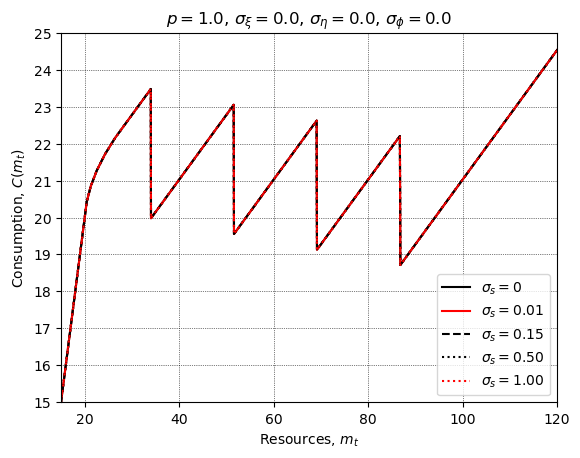

In [7]:
fig1_1_params = copy.deepcopy(retiring_params)
fig1_1_params['Rfree'] = 1.0
fig1_1_params['DiscFac'] = 0.98
fig1_1_params['prob_opt'] = 1.0
fig1_1_params['sigma_xi'] = 0.000
fig1_1_params['TasteShkCount'] = 1
fig1_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig1_1_params['T']
fig1_1_params['TranShkCount'] = 1
modelfig1_1 = RetiringDeaton(**fig1_1_params)
modelfig1_1.solve()

fig1_2_params = copy.deepcopy(fig1_1_params)
fig1_2_params['sigma_s'] = 0.01
modelfig1_2 = RetiringDeaton(**fig1_2_params)
modelfig1_2.solve()

fig1_3_params = copy.deepcopy(fig1_1_params)
fig1_3_params['sigma_s'] = 0.15
modelfig1_3 = RetiringDeaton(**fig1_3_params)
modelfig1_3.solve()

fig1_4_params = copy.deepcopy(fig1_1_params)
fig1_4_params['sigma_s'] = 0.5
modelfig1_4 = RetiringDeaton(**fig1_4_params)
modelfig1_4.solve()

fig1_5_params = copy.deepcopy(fig1_1_params)
fig1_5_params['sigma_s'] = 1.0
modelfig1_5 = RetiringDeaton(**fig1_5_params)
modelfig1_5.solve()

t=15

plt.plot(modelfig1_1.mGrid, modelfig1_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig1_2.mGrid, modelfig1_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig1_3.mGrid, modelfig1_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig1_4.mGrid, modelfig1_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig1_5.mGrid, modelfig1_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p1_xi0_eta0.pdf", dpi=150)
plt.show()

### Search with $p = 0.5$

Same isolation as above, but the option arrives with exogenous probability $1/2$ if the household does not search. Varies $\sigma_s$ to show how search raises the chance of receiving the (certain) retirement option. Taste, income risk, and $\phi$ remain off.


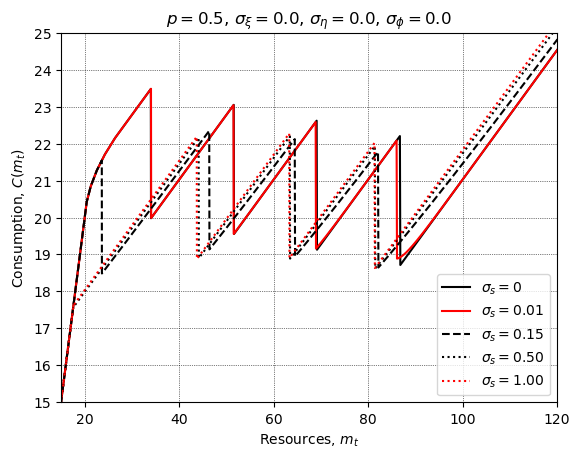

In [8]:
fig1a_1_params = copy.deepcopy(retiring_params)
fig1a_1_params['Rfree'] = 1.0
fig1a_1_params['DiscFac'] = 0.98
fig1a_1_params['prob_opt'] = 0.5
fig1a_1_params['sigma_xi'] = 0.000
fig1a_1_params['TasteShkCount'] = 1
fig1a_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig1a_1_params['T']
fig1a_1_params['TranShkCount'] = 1
modelfig1a_1 = RetiringDeaton(**fig1a_1_params)
modelfig1a_1.solve()

fig1a_2_params = copy.deepcopy(fig1a_1_params)
fig1a_2_params['sigma_s'] = 0.01
modelfig1a_2 = RetiringDeaton(**fig1a_2_params)
modelfig1a_2.solve()

fig1a_3_params = copy.deepcopy(fig1a_1_params)
fig1a_3_params['sigma_s'] = 0.15
modelfig1a_3 = RetiringDeaton(**fig1a_3_params)
modelfig1a_3.solve()

fig1a_4_params = copy.deepcopy(fig1a_1_params)
fig1a_4_params['sigma_s'] = 0.5
modelfig1a_4 = RetiringDeaton(**fig1a_4_params)
modelfig1a_4.solve()

fig1a_5_params = copy.deepcopy(fig1a_1_params)
fig1a_5_params['sigma_s'] = 1.0
modelfig1a_5 = RetiringDeaton(**fig1a_5_params)
modelfig1a_5.solve()

t=15

plt.plot(modelfig1a_1.mGrid, modelfig1a_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig1a_2.mGrid, modelfig1a_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig1a_3.mGrid, modelfig1a_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig1a_4.mGrid, modelfig1a_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig1a_5.mGrid, modelfig1a_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.5$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0p5_xi0_eta0.pdf", dpi=150)
plt.show()

### Search only ($p = 0$)

The option arrives only if the household searches. Varies $\sigma_s$ with no taste shocks, no income risk, and no $\phi$. This is the pure search-smoothing case: effort governs whether the discrete retirement choice is available.


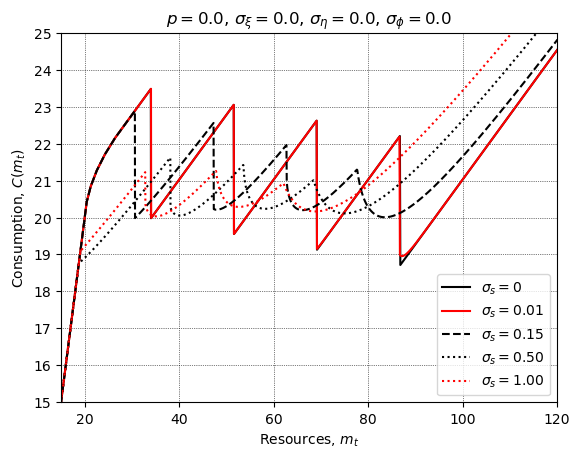

In [9]:
fig2_1_params = copy.deepcopy(retiring_params)
fig2_1_params['Rfree'] = 1.0
fig2_1_params['DiscFac'] = 0.98
fig2_1_params['prob_opt'] = 0.0
fig2_1_params['sigma_xi'] = 0.000
fig2_1_params['TasteShkCount'] = 1
fig2_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig2_1_params['T']
fig2_1_params['TranShkCount'] = 1
modelfig2_1 = RetiringDeaton(**fig2_1_params)
modelfig2_1.solve()

fig2_2_params = copy.deepcopy(fig2_1_params)
fig2_2_params['sigma_s'] = 0.01
modelfig2_2 = RetiringDeaton(**fig2_2_params)
modelfig2_2.solve()

fig2_3_params = copy.deepcopy(fig2_1_params)
fig2_3_params['sigma_s'] = 0.15
modelfig2_3 = RetiringDeaton(**fig2_3_params)
modelfig2_3.solve()

fig2_4_params = copy.deepcopy(fig2_1_params)
fig2_4_params['sigma_s'] = 0.5
modelfig2_4 = RetiringDeaton(**fig2_4_params)
modelfig2_4.solve()

fig2_5_params = copy.deepcopy(fig2_1_params)
fig2_5_params['sigma_s'] = 1.0
modelfig2_5 = RetiringDeaton(**fig2_5_params)
modelfig2_5.solve()

t=15

plt.plot(modelfig2_1.mGrid, modelfig2_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig2_2.mGrid, modelfig2_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig2_3.mGrid, modelfig2_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig2_4.mGrid, modelfig2_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig2_5.mGrid, modelfig2_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0_xi0_eta0.pdf", dpi=150)
plt.show()


### Search plus taste shocks ($\sigma_\xi = 0.01$)

$p=0$ as in the search-only figure, now with a modest EV taste shock on the work value. Varies $\sigma_s$ to see how search and taste interact. Income risk and $\phi$ are off.


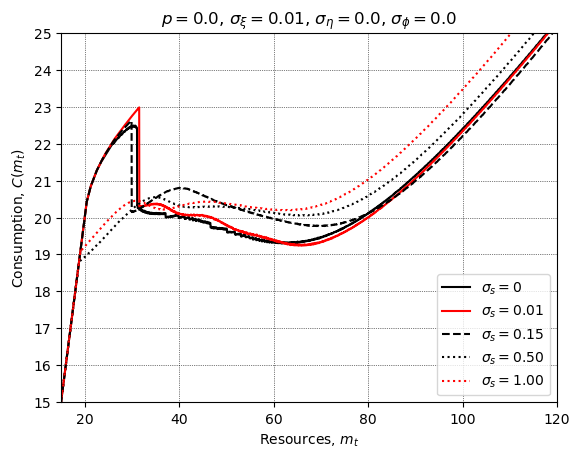

In [10]:
fig3_1_params = copy.deepcopy(retiring_params)
fig3_1_params['Rfree'] = 1.0
fig3_1_params['DiscFac'] = 0.98
fig3_1_params['prob_opt'] = 0.0
fig3_1_params['sigma_xi'] = 0.01
fig3_1_params['TasteShkCount'] = 211
fig3_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig3_1_params['T']
fig3_1_params['TranShkCount'] = 1
modelfig3_1 = RetiringDeaton(**fig3_1_params)
modelfig3_1.solve()

fig3_2_params = copy.deepcopy(fig3_1_params)
fig3_2_params['sigma_s'] = 0.01
modelfig3_2 = RetiringDeaton(**fig3_2_params)
modelfig3_2.solve()

fig3_3_params = copy.deepcopy(fig3_1_params)
fig3_3_params['sigma_s'] = 0.15
modelfig3_3 = RetiringDeaton(**fig3_3_params)
modelfig3_3.solve()

fig3_4_params = copy.deepcopy(fig3_1_params)
fig3_4_params['sigma_s'] = 0.5
modelfig3_4 = RetiringDeaton(**fig3_4_params)
modelfig3_4.solve()

fig3_5_params = copy.deepcopy(fig3_1_params)
fig3_5_params['sigma_s'] = 1.0
modelfig3_5 = RetiringDeaton(**fig3_5_params)
modelfig3_5.solve()

t=15

plt.plot(modelfig3_1.mGrid, modelfig3_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig3_2.mGrid, modelfig3_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig3_3.mGrid, modelfig3_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig3_4.mGrid, modelfig3_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig3_5.mGrid, modelfig3_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_{\\xi} = 0.01$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0_xi0p01_eta0.pdf", dpi=150)
plt.show()



### Search plus smaller taste shocks ($\sigma_\xi = 0.005$)

Same design as the previous figure, but with a weaker taste scale. Varies $\sigma_s$; income risk and $\phi$ remain off.


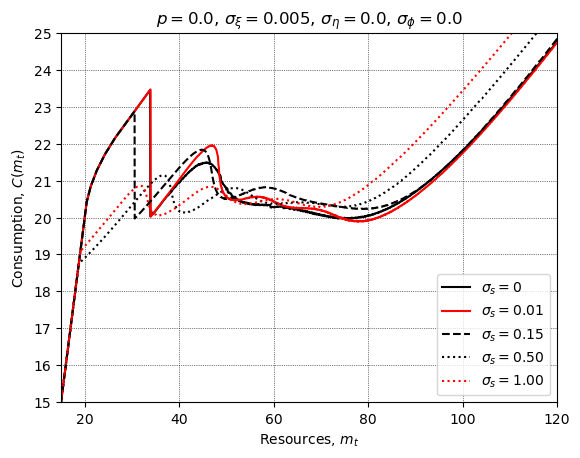

In [11]:
fig3a_1_params = copy.deepcopy(retiring_params)
fig3a_1_params['Rfree'] = 1.0
fig3a_1_params['DiscFac'] = 0.98
fig3a_1_params['prob_opt'] = 0.0
fig3a_1_params['sigma_xi'] = 0.005
fig3a_1_params['TasteShkCount'] = 211
fig3a_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig3a_1_params['T']
fig3a_1_params['TranShkCount'] = 1
modelfig3a_1 = RetiringDeaton(**fig3a_1_params)
modelfig3a_1.solve()

fig3a_2_params = copy.deepcopy(fig3a_1_params)
fig3a_2_params['sigma_s'] = 0.01
modelfig3a_2 = RetiringDeaton(**fig3a_2_params)
modelfig3a_2.solve()

fig3a_3_params = copy.deepcopy(fig3a_1_params)
fig3a_3_params['sigma_s'] = 0.15
modelfig3a_3 = RetiringDeaton(**fig3a_3_params)
modelfig3a_3.solve()

fig3a_4_params = copy.deepcopy(fig3a_1_params)
fig3a_4_params['sigma_s'] = 0.5
modelfig3a_4 = RetiringDeaton(**fig3a_4_params)
modelfig3a_4.solve()

fig3a_5_params = copy.deepcopy(fig3a_1_params)
fig3a_5_params['sigma_s'] = 1.0
modelfig3a_5 = RetiringDeaton(**fig3a_5_params)
modelfig3a_5.solve()

t=15

plt.plot(modelfig3a_1.mGrid, modelfig3a_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig3a_2.mGrid, modelfig3a_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig3a_3.mGrid, modelfig3a_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig3a_4.mGrid, modelfig3a_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig3a_5.mGrid, modelfig3a_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_{\\xi} = 0.005$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0_xi0p005_eta0.pdf", dpi=150)
plt.show()



### Search, taste, and income risk ($\sigma_\xi = 0.005$)

Adds transitory income risk $\sigma_\eta = \sqrt{0.005}$ on top of search ($p=0$) and taste. Varies $\sigma_s$. $\phi$ is still off.


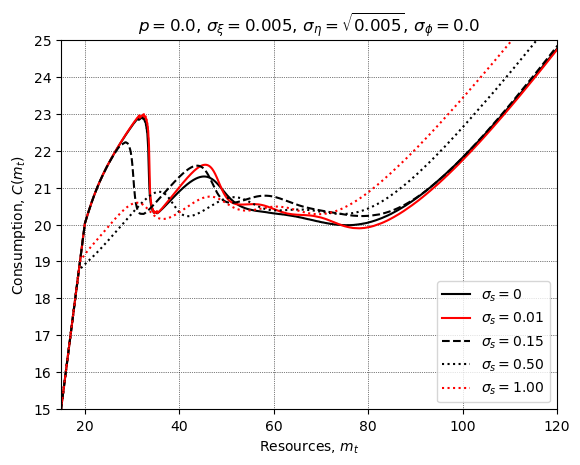

In [12]:
fig3b_1_params = copy.deepcopy(retiring_params)
fig3b_1_params['Rfree'] = 1.0
fig3b_1_params['DiscFac'] = 0.98
fig3b_1_params['prob_opt'] = 0.0
fig3b_1_params['sigma_xi'] = 0.005
fig3b_1_params['TasteShkCount'] = 211
fig3b_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig3b_1_params['T']
fig3b_1_params['TranShkCount'] = 31
modelfig3b_1 = RetiringDeaton(**fig3b_1_params)
modelfig3b_1.solve()

fig3b_2_params = copy.deepcopy(fig3b_1_params)
fig3b_2_params['sigma_s'] = 0.01
modelfig3b_2 = RetiringDeaton(**fig3b_2_params)
modelfig3b_2.solve()

fig3b_3_params = copy.deepcopy(fig3b_1_params)
fig3b_3_params['sigma_s'] = 0.15
modelfig3b_3 = RetiringDeaton(**fig3b_3_params)
modelfig3b_3.solve()

fig3b_4_params = copy.deepcopy(fig3b_1_params)
fig3b_4_params['sigma_s'] = 0.5
modelfig3b_4 = RetiringDeaton(**fig3b_4_params)
modelfig3b_4.solve()

fig3b_5_params = copy.deepcopy(fig3b_1_params)
fig3b_5_params['sigma_s'] = 1.0
modelfig3b_5 = RetiringDeaton(**fig3b_5_params)
modelfig3b_5.solve()

t=15

plt.plot(modelfig3b_1.mGrid, modelfig3b_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig3b_2.mGrid, modelfig3b_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig3b_3.mGrid, modelfig3b_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig3b_4.mGrid, modelfig3b_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig3b_5.mGrid, modelfig3b_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_{\\xi} = 0.005$, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0_xi0p005_etaSqrt0p005.pdf", dpi=150)
plt.show()


### Search, taste, and income risk ($\sigma_\xi = 0.01$)

Same three-friction combination with a larger taste scale. Varies $\sigma_s$; $\phi$ is off.


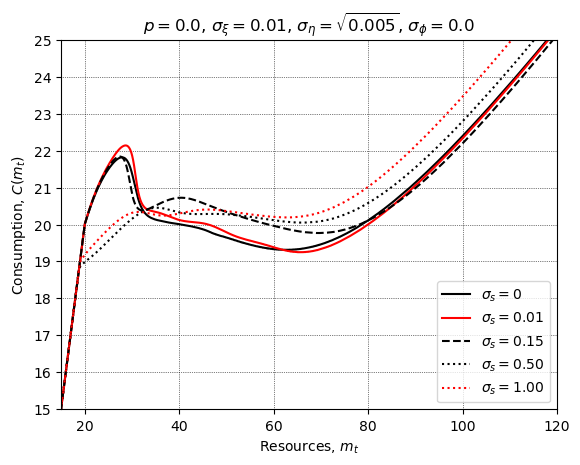

In [13]:
fig4_1_params = copy.deepcopy(retiring_params)
fig4_1_params['Rfree'] = 1.0
fig4_1_params['DiscFac'] = 0.98
fig4_1_params['prob_opt'] = 0.0
fig4_1_params['sigma_xi'] = 0.01
fig4_1_params['TasteShkCount'] = 211
fig4_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig4_1_params['T']
fig4_1_params['TranShkCount'] = 31
modelfig4_1 = RetiringDeaton(**fig4_1_params)
modelfig4_1.solve()

fig4_2_params = copy.deepcopy(fig4_1_params)
fig4_2_params['sigma_s'] = 0.01
modelfig4_2 = RetiringDeaton(**fig4_2_params)
modelfig4_2.solve()

fig4_3_params = copy.deepcopy(fig4_1_params)
fig4_3_params['sigma_s'] = 0.15
modelfig4_3 = RetiringDeaton(**fig4_3_params)
modelfig4_3.solve()

fig4_4_params = copy.deepcopy(fig4_1_params)
fig4_4_params['sigma_s'] = 0.5
modelfig4_4 = RetiringDeaton(**fig4_4_params)
modelfig4_4.solve()

fig4_5_params = copy.deepcopy(fig4_1_params)
fig4_5_params['sigma_s'] = 1.0
modelfig4_5 = RetiringDeaton(**fig4_5_params)
modelfig4_5.solve()

t=15

plt.plot(modelfig4_1.mGrid, modelfig4_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig4_2.mGrid, modelfig4_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig4_3.mGrid, modelfig4_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig4_4.mGrid, modelfig4_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig4_5.mGrid, modelfig4_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_{\\xi} = 0.01$, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0_xi0p01_etaSqrt0p005.pdf", dpi=150)
plt.show()

### Baseline three-friction specification

$p=0$, $\sigma_\xi = 0.02$, $\sigma_\eta = \sqrt{0.005}$. This is the notebook's baseline combination of search, taste, and income risk (no $\phi$). Varies $\sigma_s$. The next comparative-static figures hold this baseline and change one dimension at a time.


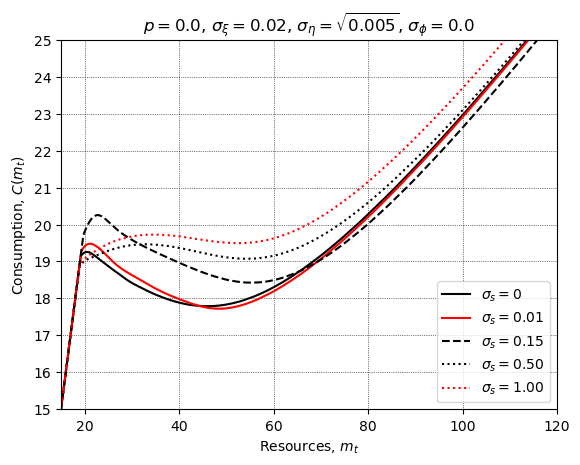

In [14]:
fig4a_1_params = copy.deepcopy(retiring_params)
fig4a_1_params['Rfree'] = 1.0
fig4a_1_params['DiscFac'] = 0.98
fig4a_1_params['prob_opt'] = 0.0
fig4a_1_params['sigma_xi'] = 0.02
fig4a_1_params['TasteShkCount'] = 511
fig4a_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig4a_1_params['T']
fig4a_1_params['TranShkCount'] = 31
modelfig4a_1 = RetiringDeaton(**fig4a_1_params)
modelfig4a_1.solve()

fig4a_2_params = copy.deepcopy(fig4a_1_params)
fig4a_2_params['sigma_s'] = 0.01
modelfig4a_2 = RetiringDeaton(**fig4a_2_params)
modelfig4a_2.solve()

fig4a_3_params = copy.deepcopy(fig4a_1_params)
fig4a_3_params['sigma_s'] = 0.15
modelfig4a_3 = RetiringDeaton(**fig4a_3_params)
modelfig4a_3.solve()

fig4a_4_params = copy.deepcopy(fig4a_1_params)
fig4a_4_params['sigma_s'] = 0.5
modelfig4a_4 = RetiringDeaton(**fig4a_4_params)
modelfig4a_4.solve()

fig4a_5_params = copy.deepcopy(fig4a_1_params)
fig4a_5_params['sigma_s'] = 1.0
modelfig4a_5 = RetiringDeaton(**fig4a_5_params)
modelfig4a_5.solve()

t=15

plt.plot(modelfig4a_1.mGrid, modelfig4a_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig4a_2.mGrid, modelfig4a_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig4a_3.mGrid, modelfig4a_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig4a_4.mGrid, modelfig4a_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig4a_5.mGrid, modelfig4a_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')






plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_{\\xi} = 0.02$, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0_xi0p02_etaSqrt0p005.pdf", dpi=150)
plt.show()


### Baseline taste, no income risk

Same as the baseline three-friction figure but with $\sigma_\eta = 0$. Isolates how much of the smoothing came from income risk versus search and taste.


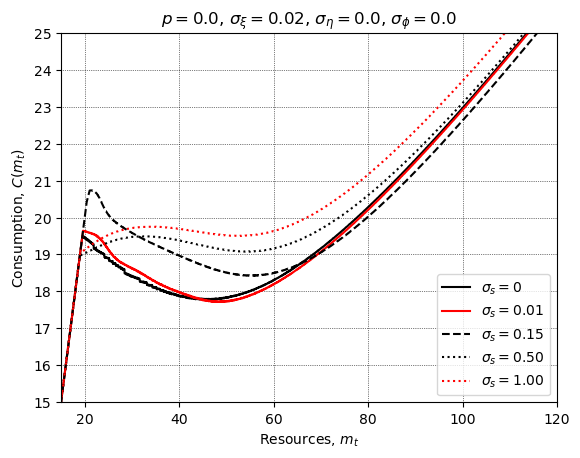

In [15]:
##================

fig4b_1_params = copy.deepcopy(retiring_params)
fig4b_1_params['Rfree'] = 1.0
fig4b_1_params['DiscFac'] = 0.98
fig4b_1_params['prob_opt'] = 0.0
fig4b_1_params['sigma_xi'] = 0.02
fig4b_1_params['TasteShkCount'] = 511
fig4b_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig4b_1_params['T']
fig4b_1_params['TranShkCount'] = 1
modelfig4b_1 = RetiringDeaton(**fig4b_1_params)
modelfig4b_1.solve()

fig4b_2_params = copy.deepcopy(fig4b_1_params)
fig4b_2_params['sigma_s'] = 0.01
modelfig4b_2 = RetiringDeaton(**fig4b_2_params)
modelfig4b_2.solve()

fig4b_3_params = copy.deepcopy(fig4b_1_params)
fig4b_3_params['sigma_s'] = 0.15
modelfig4b_3 = RetiringDeaton(**fig4b_3_params)
modelfig4b_3.solve()

fig4b_4_params = copy.deepcopy(fig4b_1_params)
fig4b_4_params['sigma_s'] = 0.5
modelfig4b_4 = RetiringDeaton(**fig4b_4_params)
modelfig4b_4.solve()

fig4b_5_params = copy.deepcopy(fig4b_1_params)
fig4b_5_params['sigma_s'] = 1.0
modelfig4b_5 = RetiringDeaton(**fig4b_5_params)
modelfig4b_5.solve()

t=15

plt.plot(modelfig4b_1.mGrid, modelfig4b_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig4b_2.mGrid, modelfig4b_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig4b_3.mGrid, modelfig4b_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig4b_4.mGrid, modelfig4b_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig4b_5.mGrid, modelfig4b_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_{\\xi} = 0.02$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/p0_xi0p02_eta0.pdf", dpi=150)
plt.show()

### Vary the exogenous option probability $p$

Holds the baseline search, taste, and income-risk scales and varies $p \in \{0, 0.1, 0.5\}$. Shows how much of the option's arrival is left to search versus the exogenous probability. $\phi$ is off.


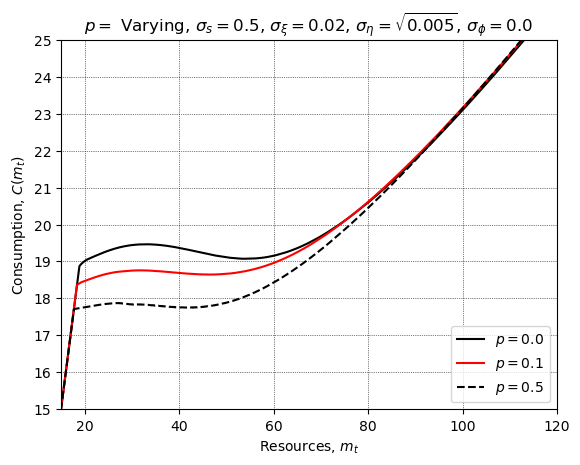

In [16]:
fig5_1_params = copy.deepcopy(retiring_params)
fig5_1_params['Rfree'] = 1.0
fig5_1_params['DiscFac'] = 0.98
fig5_1_params['prob_opt'] = 0.0
fig5_1_params['sigma_xi'] = 0.02
fig5_1_params['sigma_s'] = 0.5
fig5_1_params['TasteShkCount'] = 211
fig5_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig5_1_params['T']
fig5_1_params['TranShkCount'] = 31
modelfig5_1 = RetiringDeaton(**fig5_1_params)
modelfig5_1.solve()

fig5_2_params = copy.deepcopy(fig5_1_params)
fig5_2_params['prob_opt'] = 0.1
modelfig5_2 = RetiringDeaton(**fig5_2_params)
modelfig5_2.solve()

fig5_3_params = copy.deepcopy(fig5_1_params)
fig5_3_params['prob_opt'] = 0.5
modelfig5_3 = RetiringDeaton(**fig5_3_params)
modelfig5_3.solve()

t=15

plt.plot(modelfig5_1.mGrid, modelfig5_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig5_2.mGrid, modelfig5_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig5_3.mGrid, modelfig5_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p =$ Varying, $\sigma_s = 0.5$, $\sigma_{\\xi} = 0.02$, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$p = 0.0$','$p = 0.1$','$p = 0.5$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/VaryP.pdf", dpi=150)
plt.show()


### Vary search at the three-friction baseline

Holds $p=0$, taste, and income risk at baseline values and varies $\sigma_s$ over a coarser grid $\{0.5, 1.0, 2.0\}$. $\phi$ is off.


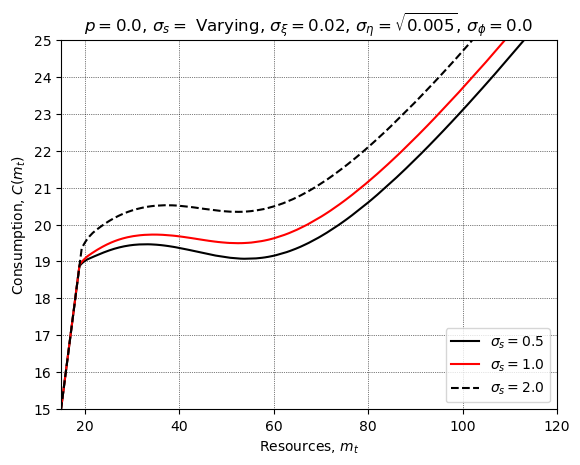

In [17]:
fig6_1_params = copy.deepcopy(retiring_params)
fig6_1_params['Rfree'] = 1.0
fig6_1_params['DiscFac'] = 0.98
fig6_1_params['prob_opt'] = 0.0
fig6_1_params['sigma_xi'] = 0.02
fig6_1_params['sigma_s'] = 0.5
fig6_1_params['TasteShkCount'] = 211
fig6_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig6_1_params['T']
fig6_1_params['TranShkCount'] = 31
modelfig6_1 = RetiringDeaton(**fig6_1_params)
modelfig6_1.solve()

fig6_2_params = copy.deepcopy(fig6_1_params)
fig6_2_params['sigma_s'] = 1.0
modelfig6_2 = RetiringDeaton(**fig6_2_params)
modelfig6_2.solve()

fig6_3_params = copy.deepcopy(fig6_1_params)
fig6_3_params['sigma_s'] = 2.0
modelfig6_3 = RetiringDeaton(**fig6_3_params)
modelfig6_3.solve()

t=15

plt.plot(modelfig6_1.mGrid, modelfig6_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig6_2.mGrid, modelfig6_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig6_3.mGrid, modelfig6_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_s =$ Varying, $\sigma_{\\xi} = 0.02$, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0.5$','$\sigma_s = 1.0$','$\sigma_s = 2.0$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/VaryS.pdf", dpi=150)
plt.show()



### Vary taste-shock scale

Holds $p=0$, search, and income risk at baseline values and varies $\sigma_\xi$. $\phi$ is off.


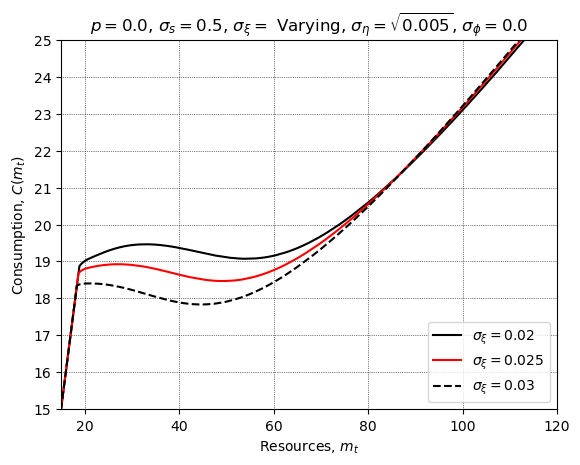

In [18]:
fig7_1_params = copy.deepcopy(retiring_params)
fig7_1_params['Rfree'] = 1.0
fig7_1_params['DiscFac'] = 0.98
fig7_1_params['prob_opt'] = 0.0
fig7_1_params['sigma_xi'] = 0.02
fig7_1_params['sigma_s'] = 0.5
fig7_1_params['TasteShkCount'] = 211
fig7_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig7_1_params['T']
fig7_1_params['TranShkCount'] = 31
modelfig7_1 = RetiringDeaton(**fig7_1_params)
modelfig7_1.solve()

fig7_2_params = copy.deepcopy(fig7_1_params)
fig7_2_params['sigma_xi'] = 0.025
modelfig7_2 = RetiringDeaton(**fig7_2_params)
modelfig7_2.solve()

fig7_3_params = copy.deepcopy(fig7_1_params)
fig7_3_params['sigma_xi'] = 0.03
modelfig7_3 = RetiringDeaton(**fig7_3_params)
modelfig7_3.solve()

t=15

plt.plot(modelfig7_1.mGrid, modelfig7_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig7_2.mGrid, modelfig7_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig7_3.mGrid, modelfig7_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_s = 0.5$, $\sigma_{\\xi} =$ Varying, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_{\\xi} = 0.02$','$\sigma_{\\xi} = 0.025$','$\sigma_{\\xi} = 0.03$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/VaryXi.pdf", dpi=150)
plt.show()


### Vary income-risk scale

Holds $p=0$, search, and taste at baseline values and varies $\sigma_\eta$. $\phi$ is off.


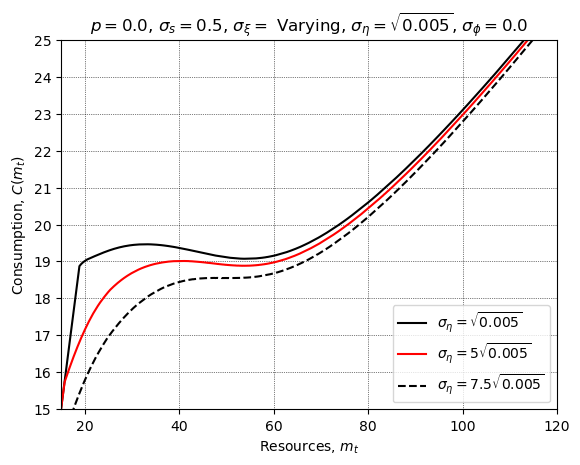

In [19]:
fig8_1_params = copy.deepcopy(retiring_params)
fig8_1_params['Rfree'] = 1.0
fig8_1_params['DiscFac'] = 0.98
fig8_1_params['prob_opt'] = 0.0
fig8_1_params['sigma_xi'] = 0.02
fig8_1_params['sigma_s'] = 0.5
fig8_1_params['TasteShkCount'] = 211
fig8_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig8_1_params['T']
fig8_1_params['TranShkCount'] = 31
modelfig8_1 = RetiringDeaton(**fig8_1_params)
modelfig8_1.solve()

fig8_2_params = copy.deepcopy(fig8_1_params)
fig8_2_params['TranShkStd'] = [5.0*np.sqrt(0.005)]*fig8_1_params['T']
modelfig8_2 = RetiringDeaton(**fig8_2_params)
modelfig8_2.solve()

fig8_3_params = copy.deepcopy(fig8_1_params)
fig8_3_params['TranShkStd'] = [7.5*np.sqrt(0.005)]*fig8_1_params['T']
modelfig8_3 = RetiringDeaton(**fig8_3_params)
modelfig8_3.solve()

t=15

plt.plot(modelfig8_1.mGrid, modelfig8_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig8_2.mGrid, modelfig8_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig8_3.mGrid, modelfig8_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_s = 0.5$, $\sigma_{\\xi} =$ Varying, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_{\\phi} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_{\eta} = \sqrt{0.005}$','$\sigma_{\eta} = 5\sqrt{0.005}$','$\sigma_{\eta} = 7.5\sqrt{0.005}$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/VaryEta.pdf", dpi=150)
plt.show()


## Account-value dispersion $\phi$ only

No search, taste, or income risk. The option arrives with certainty ($p=1$), the household observes $\phi$, and then claims or denies by a hard maximum. These figures ask whether $\phi$ alone can smooth the retirement kink.


### Account-value dispersion only: vary $\sigma_\phi$

Isolates $\phi$. Sets $p=1$ so a draw always arrives, and shuts off search, taste, and income risk. Varies $\sigma_\phi \in \{0, 0.05, 0.1, 0.2\}$ with 5 quadrature nodes (one node when $\sigma_\phi=0$, because HARK collapses a zero-variance distribution). The household accepts or denies each realized $\phi$ by a hard maximum.


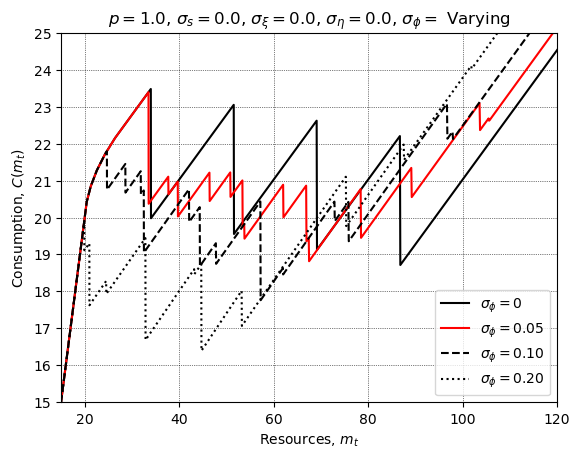

In [20]:
#
##================
#
# Price dispersion only: p=1 so the option always arrives; no search, taste, or income risk.
# sigma_phi = 0, 0.05, 0.1, 0.2 with 5 quadrature nodes (HARK collapses sigma_phi=0 to 1 node).
fig9_1_params = copy.deepcopy(retiring_params)
fig9_1_params['Rfree'] = 1.0
fig9_1_params['DiscFac'] = 0.98
fig9_1_params['prob_opt'] = 1.0
fig9_1_params['sigma_s'] = 0.0
fig9_1_params['sigma_xi'] = 0.0
fig9_1_params['TasteShkCount'] = 1
fig9_1_params['TranShkStd'] = [0.0]*fig9_1_params['T']
fig9_1_params['TranShkCount'] = 1
fig9_1_params['sigma_phi'] = 0.0
fig9_1_params['PhiShkCount'] = 1
modelfig9_1 = RetiringDeaton(**fig9_1_params)
modelfig9_1.solve()

fig9_2_params = copy.deepcopy(fig9_1_params)
fig9_2_params['sigma_phi'] = 0.05
fig9_2_params['PhiShkCount'] = 5
modelfig9_2 = RetiringDeaton(**fig9_2_params)
modelfig9_2.solve()

fig9_3_params = copy.deepcopy(fig9_1_params)
fig9_3_params['sigma_phi'] = 0.1
fig9_3_params['PhiShkCount'] = 5
modelfig9_3 = RetiringDeaton(**fig9_3_params)
modelfig9_3.solve()

fig9_4_params = copy.deepcopy(fig9_1_params)
fig9_4_params['sigma_phi'] = 0.2
fig9_4_params['PhiShkCount'] = 5
modelfig9_4 = RetiringDeaton(**fig9_4_params)
modelfig9_4.solve()

t=15

plt.plot(modelfig9_1.mGrid, modelfig9_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig9_2.mGrid, modelfig9_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig9_3.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig9_4.mGrid, modelfig9_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} =$ Varying")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_{\\phi} = 0$','$\sigma_{\\phi} = 0.05$','$\sigma_{\\phi} = 0.10$','$\sigma_{\\phi} = 0.20$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/VaryPhi.pdf", dpi=150)
plt.show()


### Account-value dispersion only: vary the number of $\phi$ nodes

Same isolation ($p=1$, no search/taste/income). Fixes $\sigma_\phi = 0.1$ and varies the quadrature size $N_\phi \in \{1, 5, 13, 21\}$. One node is mean-only (no dispersion in the grid).


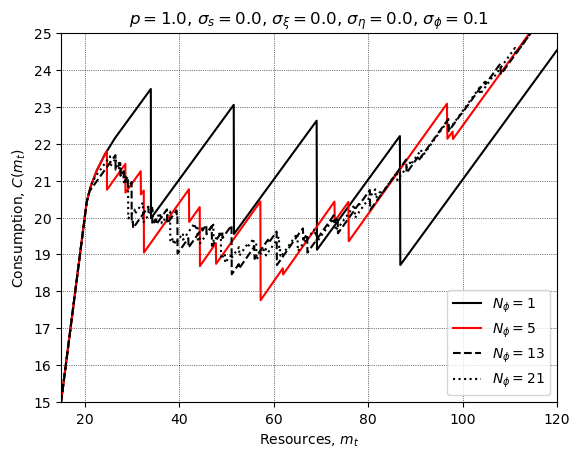

In [21]:
#
##================
#
# Price dispersion only: sigma_phi = 0.1, vary number of quadrature nodes.
fig10_1_params = copy.deepcopy(retiring_params)
fig10_1_params['Rfree'] = 1.0
fig10_1_params['DiscFac'] = 0.98
fig10_1_params['prob_opt'] = 1.0
fig10_1_params['sigma_s'] = 0.0
fig10_1_params['sigma_xi'] = 0.0
fig10_1_params['TasteShkCount'] = 1
fig10_1_params['TranShkStd'] = [0.0]*fig10_1_params['T']
fig10_1_params['TranShkCount'] = 1
fig10_1_params['sigma_phi'] = 0.1
fig10_1_params['PhiShkCount'] = 1
modelfig10_1 = RetiringDeaton(**fig10_1_params)
modelfig10_1.solve()

fig10_2_params = copy.deepcopy(fig10_1_params)
fig10_2_params['PhiShkCount'] = 5
modelfig10_2 = RetiringDeaton(**fig10_2_params)
modelfig10_2.solve()

fig10_3_params = copy.deepcopy(fig10_1_params)
fig10_3_params['PhiShkCount'] = 13
modelfig10_3 = RetiringDeaton(**fig10_3_params)
modelfig10_3.solve()

fig10_4_params = copy.deepcopy(fig10_1_params)
fig10_4_params['PhiShkCount'] = 21
modelfig10_4 = RetiringDeaton(**fig10_4_params)
modelfig10_4.solve()

t=15

plt.plot(modelfig10_1.mGrid, modelfig10_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig10_2.mGrid, modelfig10_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig10_3.mGrid, modelfig10_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig10_4.mGrid, modelfig10_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.1$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$N_{\\phi} = 1$','$N_{\\phi} = 5$','$N_{\\phi} = 13$','$N_{\\phi} = 21$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/VaryPhiCount.pdf", dpi=150)
plt.show()


## Search and account-value dispersion together

Baseline: $\sigma_s = 0.1$, $\sigma_\phi = 0.1$, $N_\phi = 5$, with $p=0$ (search is the only arrival channel). Each figure varies one of those three, holding the other two fixed. Taste and income risk are off.


### Search and $\phi$ together: vary search

Both frictions are on. Baseline $\sigma_s = 0.1$, $\sigma_\phi = 0.01$, $N_\phi = 5$. Sets $p=0$ so the option---and therefore a $\phi$ draw---arrives only through search ($p=1$ would shut search off). Varies $\sigma_s \in \{0.05, 0.1, 0.15\}$, holding $\phi$ and $N_\phi$ fixed. Taste and income risk are off.


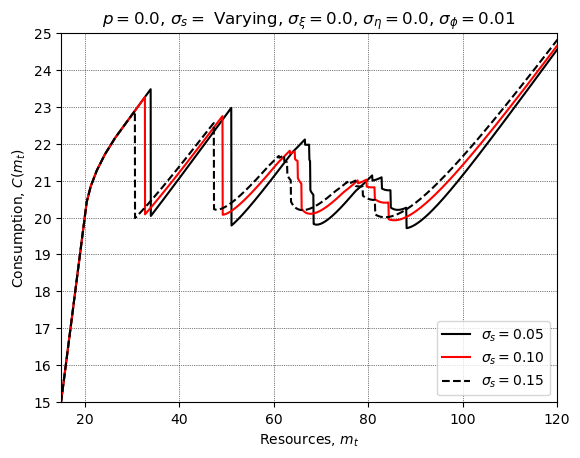

In [26]:
#
##================
#
# Search + price dispersion. Baseline: sigma_s=0.1, sigma_phi=0.1, PhiShkCount=5.
# p=0 so the option arrives only through search (p=1 would shut search off).
# Vary sigma_s = 0.05, 0.1, 0.15.
fig11_1_params = copy.deepcopy(retiring_params)
fig11_1_params['Rfree'] = 1.0
fig11_1_params['DiscFac'] = 0.98
fig11_1_params['prob_opt'] = 0.0
fig11_1_params['sigma_s'] = 0.05
fig11_1_params['sigma_xi'] = 0.0
fig11_1_params['TasteShkCount'] = 1
fig11_1_params['TranShkStd'] = [0.0]*fig11_1_params['T']
fig11_1_params['TranShkCount'] = 1
fig11_1_params['sigma_phi'] = 0.01
fig11_1_params['PhiShkCount'] = 5
modelfig11_1 = RetiringDeaton(**fig11_1_params)
modelfig11_1.solve()

fig11_2_params = copy.deepcopy(fig11_1_params)
fig11_2_params['sigma_s'] = 0.1
modelfig11_2 = RetiringDeaton(**fig11_2_params)
modelfig11_2.solve()

fig11_3_params = copy.deepcopy(fig11_1_params)
fig11_3_params['sigma_s'] = 0.15
modelfig11_3 = RetiringDeaton(**fig11_3_params)
modelfig11_3.solve()

t=15

plt.plot(modelfig11_1.mGrid, modelfig11_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig11_2.mGrid, modelfig11_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig11_3.mGrid, modelfig11_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_s =$ Varying, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.01$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0.05$','$\sigma_s = 0.10$','$\sigma_s = 0.15$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/SearchPhi_VaryS.pdf", dpi=150)
plt.show()


### Search and $\phi$ together: vary $\sigma_\phi$

Same combined baseline ($p=0$, $\sigma_s = 0.1$, $N_\phi = 5$). Varies $\sigma_\phi \in \{0.01, 0.05, 0.1\}$, holding search and the number of nodes fixed.


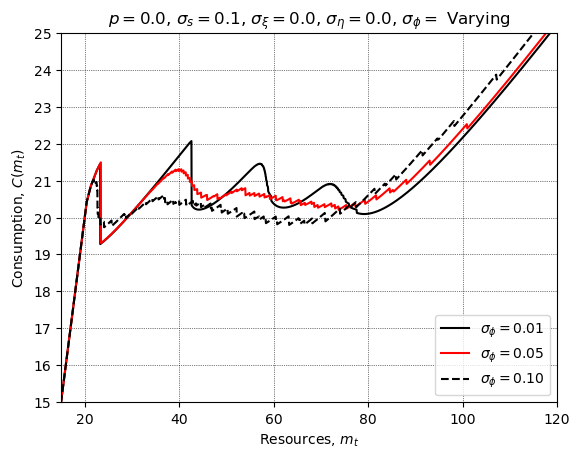

In [35]:
#
##================
#
# Search + price dispersion. Baseline: sigma_s=0.1, sigma_phi=0.1, PhiShkCount=5.
# Vary sigma_phi = 0.05, 0.1, 0.2.
fig12_1_params = copy.deepcopy(retiring_params)
fig12_1_params['Rfree'] = 1.0
fig12_1_params['DiscFac'] = 0.98
fig12_1_params['prob_opt'] = 0.0
fig12_1_params['sigma_s'] = 0.3
fig12_1_params['sigma_xi'] = 0.0
fig12_1_params['TasteShkCount'] = 1
fig12_1_params['TranShkStd'] = [0.0]*fig12_1_params['T']
fig12_1_params['TranShkCount'] = 1
fig12_1_params['sigma_phi'] = 0.01
fig12_1_params['PhiShkCount'] = 21
modelfig12_1 = RetiringDeaton(**fig12_1_params)
modelfig12_1.solve()

fig12_2_params = copy.deepcopy(fig12_1_params)
fig12_2_params['sigma_phi'] = 0.05
modelfig12_2 = RetiringDeaton(**fig12_2_params)
modelfig12_2.solve()

fig12_3_params = copy.deepcopy(fig12_1_params)
fig12_3_params['sigma_phi'] = 0.1
modelfig12_3 = RetiringDeaton(**fig12_3_params)
modelfig12_3.solve()

t=15

plt.plot(modelfig12_1.mGrid, modelfig12_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig12_2.mGrid, modelfig12_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig12_3.mGrid, modelfig12_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_s = 0.1$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} =$ Varying")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_{\\phi} = 0.01$','$\sigma_{\\phi} = 0.05$','$\sigma_{\\phi} = 0.10$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/SearchPhi_VaryPhi.pdf", dpi=150)
plt.show()


### Search and $\phi$ together: vary the number of $\phi$ nodes

Same combined baseline ($p=0$, $\sigma_s = 0.1$, $\sigma_\phi = 0.01$). Varies $N_\phi \in \{1, 5, 13, 21\}$.


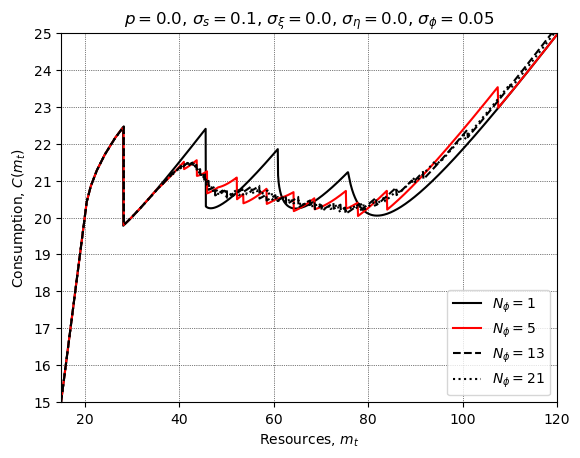

In [34]:
#
##================
#
# Search + price dispersion. Baseline: sigma_s=0.1, sigma_phi=0.1, PhiShkCount=5.
# Vary PhiShkCount = 1, 5, 13, 21.
fig13_1_params = copy.deepcopy(retiring_params)
fig13_1_params['Rfree'] = 1.0
fig13_1_params['DiscFac'] = 0.98
fig13_1_params['prob_opt'] = 0.0
fig13_1_params['sigma_s'] = 0.2
fig13_1_params['sigma_xi'] = 0.0
fig13_1_params['TasteShkCount'] = 1
fig13_1_params['TranShkStd'] = [0.0]*fig13_1_params['T']
fig13_1_params['TranShkCount'] = 1
fig13_1_params['sigma_phi'] = 0.05
fig13_1_params['PhiShkCount'] = 1
modelfig13_1 = RetiringDeaton(**fig13_1_params)
modelfig13_1.solve()

fig13_2_params = copy.deepcopy(fig13_1_params)
fig13_2_params['PhiShkCount'] = 5
modelfig13_2 = RetiringDeaton(**fig13_2_params)
modelfig13_2.solve()

fig13_3_params = copy.deepcopy(fig13_1_params)
fig13_3_params['PhiShkCount'] = 13
modelfig13_3 = RetiringDeaton(**fig13_3_params)
modelfig13_3.solve()

fig13_4_params = copy.deepcopy(fig13_1_params)
fig13_4_params['PhiShkCount'] = 21
modelfig13_4 = RetiringDeaton(**fig13_4_params)
modelfig13_4.solve()

t=15

plt.plot(modelfig13_1.mGrid, modelfig13_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig13_2.mGrid, modelfig13_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig13_3.mGrid, modelfig13_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig13_4.mGrid, modelfig13_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.0$, $\sigma_s = 0.1$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$, $\sigma_{\\phi} = 0.05$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$N_{\\phi} = 1$','$N_{\\phi} = 5$','$N_{\\phi} = 13$','$N_{\\phi} = 21$'],loc=4)
plt.savefig("../Figures/Figures_Retirement/SearchPhi_VaryPhiCount.pdf", dpi=150)
plt.show()
